In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import * 
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import Adam

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using {device}')

Using cpu


In [4]:
import requests
from io import BytesIO
import certifi

In [5]:
# 전처리
path = 'https://bit.ly/ds_boston_csv'
response = requests.get(path,verify=certifi.where(),timeout=15)
response.raise_for_status()
data = pd.read_csv(BytesIO(response.content))

# x, y 분할
target = 'medv'
features = ['lstat', 'ptratio', 'crim']
x = data.loc[:, features]
y= data.loc[:, target]

# xtrain, val 분할
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=.2, random_state=20)

# 스케일러 선언
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)

In [6]:
# 텐서 변환 + Data Loader 생성 함수
def make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32) :
    x_train_tensor = torch.tensor(x_train, dtype= torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype= torch.float32).view(-1,1)
    x_val_tensor = torch.tensor(x_val, dtype= torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype= torch.float32).view(-1,1)
    
    # TensorDataSet 생성
    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)

    # DataLoader 생성
    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle=True)
    return train_loader , x_val_tensor, y_val_tensor

In [7]:
# 넘파이 배열변환 - cpu 연산
y_train = y_train.values
y_val = y_val.values

In [8]:
# 데이터 로더 구성 by make_Dataset
train_loader, x_val_ts, y_val_ts = make_DataSet(x_train, x_val, y_train, y_val, 32)

In [9]:
# 모델 구조 설계
n_feature = x.shape[1]
model1= nn.Sequential(nn.Linear(n_feature, 1)).to(device)
loss_fn = nn.MSELoss()
optimizer = Adam(model1.parameters(), lr=0.01)
print(model1)

Sequential(
  (0): Linear(in_features=3, out_features=1, bias=True)
)


In [10]:
# 학습 함수 정의
def train(dataloader, model, loss_fn, optimizer, device):
    size= len(dataloader.dataset)
    num_batches = len(dataloader)
    tr_loss = 0
    model.train()
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    tr_loss /= num_batches
    return tr_loss.item()

In [11]:
# 검증 함수 정의
def evaluate(x_val_tensor, y_val_tensor, model, loss_fn, device):
    model.eval()
    with torch.no_grad():
        x, y = x_val_tensor.to(device), y_val_tensor.to(device)
        pred = model(x)
        val_loss = loss_fn(pred, y).item()
    return val_loss, pred

In [13]:
# 주기 100으로 학습
epochs = 100
tr_loss_list, vals_loss_list = [], [] # list로 저장하는 이유: 학습곡선
for t in range(epochs):
    tr_loss = train(train_loader, model1, loss_fn, optimizer, device)
    val_loss, _ = evaluate(x_val_ts, y_val_ts, model1, loss_fn, device)
    tr_loss_list.append(tr_loss)
    vals_loss_list.append(val_loss)
    print(f'Epoch {t+1}, train loss {tr_loss:4f}, val loss {val_loss:4f}')

Epoch 1, train loss 268.979858, val loss 201.431290
Epoch 2, train loss 264.520569, val loss 198.268921
Epoch 3, train loss 259.373474, val loss 195.189102
Epoch 4, train loss 261.617371, val loss 192.220505
Epoch 5, train loss 253.842361, val loss 189.301666
Epoch 6, train loss 248.497482, val loss 186.505814
Epoch 7, train loss 242.967789, val loss 183.770798
Epoch 8, train loss 250.308517, val loss 181.156372
Epoch 9, train loss 239.075897, val loss 178.545700
Epoch 10, train loss 234.521225, val loss 176.078445
Epoch 11, train loss 232.713791, val loss 173.651459
Epoch 12, train loss 238.567001, val loss 171.317398
Epoch 13, train loss 230.626129, val loss 169.021133
Epoch 14, train loss 227.194000, val loss 166.832489
Epoch 15, train loss 225.474747, val loss 164.635315
Epoch 16, train loss 224.206238, val loss 162.553650
Epoch 17, train loss 221.091705, val loss 160.539337
Epoch 18, train loss 218.806229, val loss 158.579453
Epoch 19, train loss 215.434296, val loss 156.648514
Ep

In [16]:
# 학습 곡선 함수
def dl_learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label= 'train_err', marker='.')
    plt.plot(epochs, val_loss_list, label= 'val_err', marker='.')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.grid()
    plt.show()

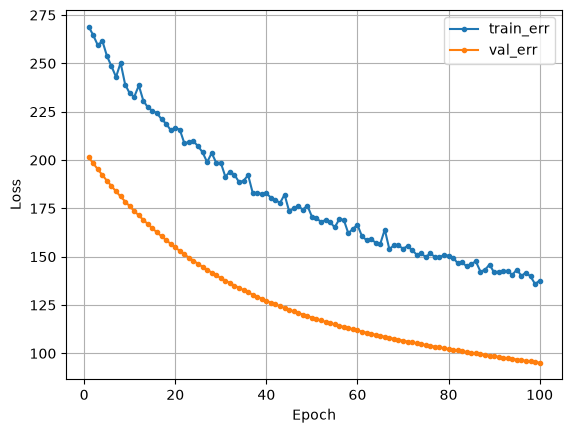

In [17]:
dl_learning_curve(tr_loss_list, vals_loss_list)

In [1]:
import torch

print('PyTorch Version :', torch.__version__)
print('CUDA Version    :', torch.version.cuda)
print('CUDA Available  :', torch.cuda.is_available())
print('GPU Count       :', torch.cuda.device_count())

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print('DEVICE          :', DEVICE)

if torch.cuda.is_available():
    print('GPU Name        :', torch.cuda.get_device_name(0))
    print('cuDNN Version   :', torch.backends.cudnn.version())

PyTorch Version : 2.15.0+cpu
CUDA Version    : None
CUDA Available  : False
GPU Count       : 0
DEVICE          : cpu
